# A rotation optimizer can lose to the allocation it replaces

Joseph Smarrelli · September 2026

This notebook recalculates selected findings from the included derived tables. It does not refit the underlying models. See the repository README for the complete source-data build and the accompanying article for interpretation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import json
from IPython.display import display, Image
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
p = root / 'projects' / '02_lineup_optimizer'

## Recalculate the result
The assertions check that the article’s reported quantities agree with the delivered tables.

In [2]:
d = pd.read_csv(p / 'allocation_evaluation.csv')
s = pd.read_csv(p / 'summary.csv').iloc[0]
assert np.isclose(d.optimized_minutes.sum(), 48)
assert np.isclose(d.baseline_minutes.sum(), 48)
optimized = np.average(d.holdout_rating, weights=d.optimized_minutes)
baseline = np.average(d.holdout_rating, weights=d.baseline_minutes)
assert np.isclose(optimized, s.optimised_holdout)
assert np.isclose(baseline, s.actual_holdout)
display(pd.Series({'optimized_holdout_rating': optimized, 'training_allocation_holdout_rating': baseline, 'difference': optimized - baseline}))

optimized_holdout_rating              11.448151
training_allocation_holdout_rating    19.384543
difference                            -7.936392
dtype: float64

## Inspect the estimates

In [3]:
display(pd.read_csv(p / 'minute_reallocation.csv'))

,player_id,optimal,actual,name,delta
0,1642264,16.0,31.130692,Stephon Castle,-15.130692
1,203084,24.0,36.475864,Harrison Barnes,-12.475864
2,1630170,20.0,28.026016,Devin Vassell,-8.026016
3,1628436,20.0,24.090165,Luke Kornet,-4.090165
4,1631110,0.0,1.948923,Jeremy Sochan,-1.948923
5,1628368,32.0,32.020797,De'Aaron Fox,-0.020797
6,1630577,36.0,32.947369,Julian Champagnie,3.052631
7,1641705,28.0,22.731927,Victor Wembanyama,5.268073
8,1642844,28.0,12.248991,Dylan Harper,15.751009
9,1629640,36.0,18.379257,Keldon Johnson,17.620743


## Figures

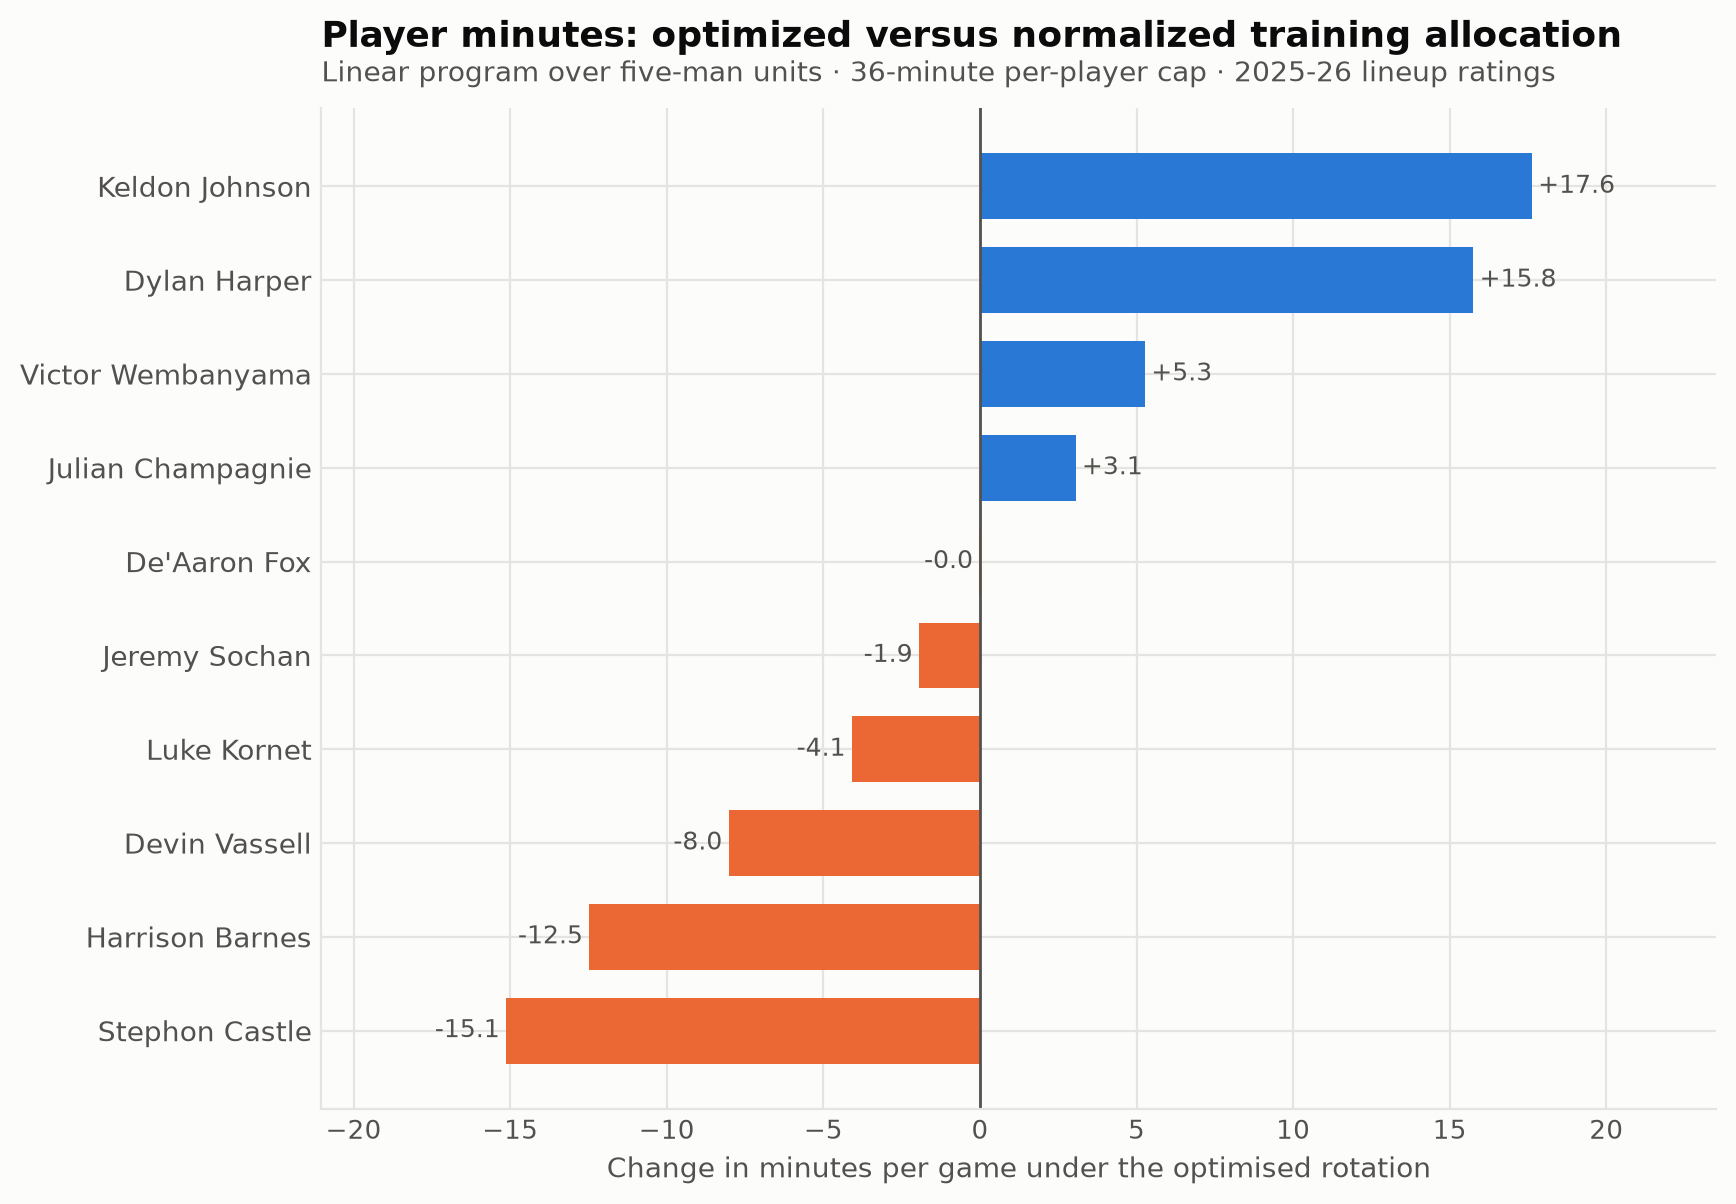

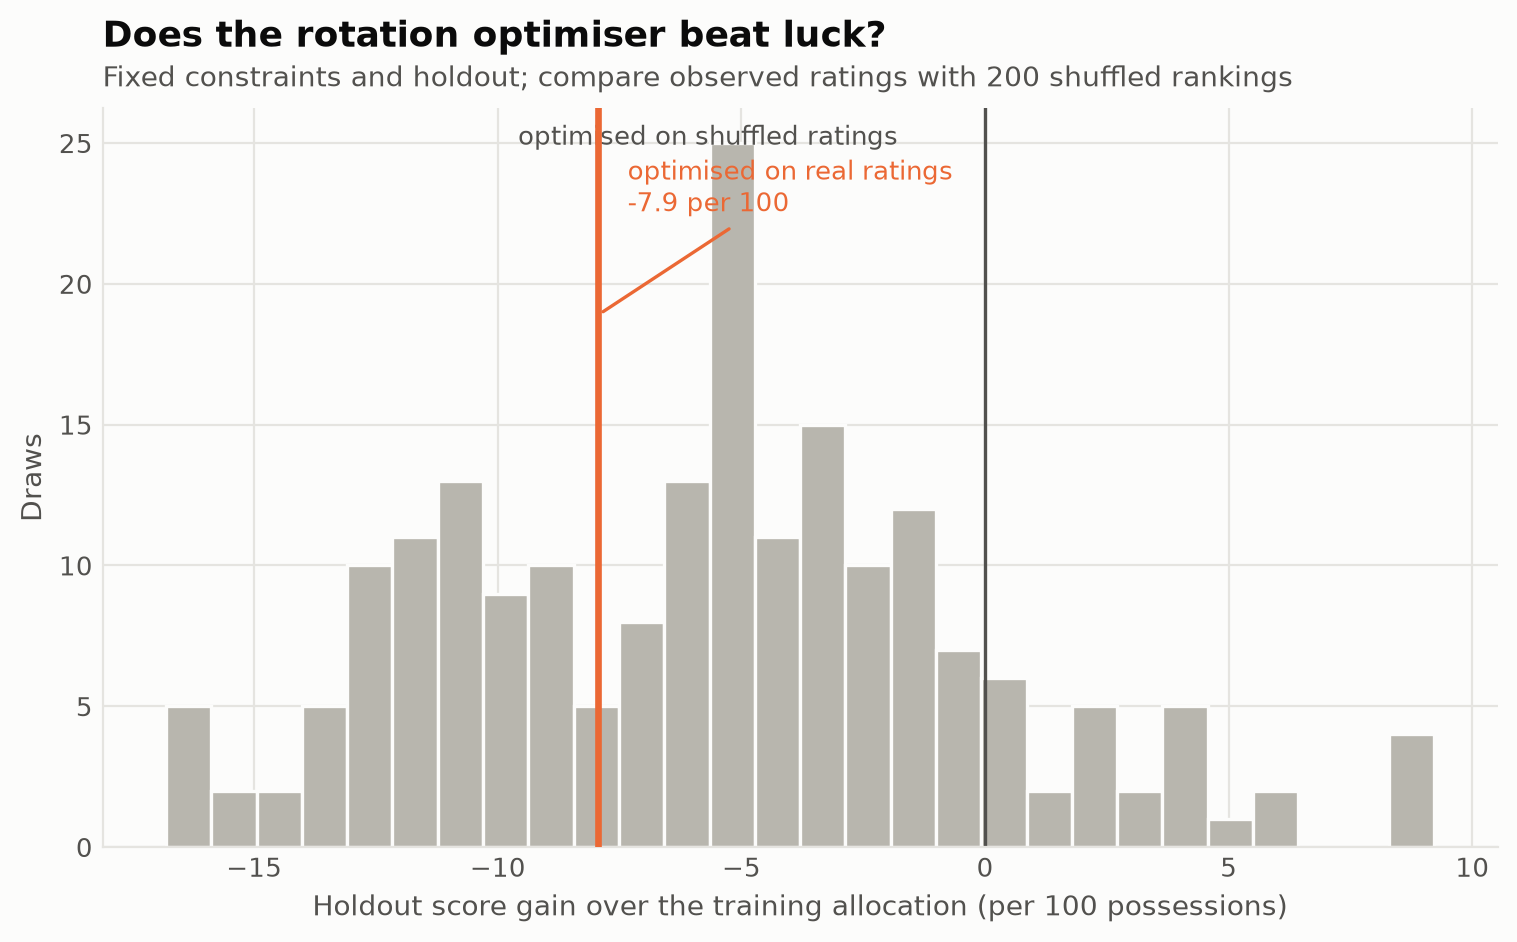

In [4]:
display(Image(filename=str(root / 'projects/02_lineup_optimizer/figures/minute_reallocation.png')))
display(Image(filename=str(root / 'projects/02_lineup_optimizer/figures/null_test.png')))

## Interpretation limits
The allocation uses training-period ratings and observed lineups. Later observational ratings do not identify the effect of actually changing a rotation. The optimized allocation loses this comparison.